<a href="https://colab.research.google.com/github/aakaash029/Aakash_Portfolio/blob/main/Assinment_No_08_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Set 01

## Question 1: Data Understanding and Preparation

### Question 1 (a) - Load and Display Initial Exploration

In [ ]:
import pandas as pd
import numpy as np
import urllib.request

# Download train.csv if it does not exist
try:
    df = pd.read_csv('train.csv')
except FileNotFoundError:
    # Using the highly reliable Seaborn dataset repository for Titanic
    url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv'
    print("Downloading train.csv...")
    urllib.request.urlretrieve(url, 'train.csv')
    df = pd.read_csv('train.csv')
    # Aligning column names to standard train.csv (capitalized columns if necessary)
    df.rename(columns={'survived': 'Survived', 'pclass': 'Pclass', 'sex': 'Sex', 'age': 'Age', 'sibsp': 'SibSp', 'parch': 'Parch', 'fare': 'Fare'}, inplace=True)

# Display first 10 rows
print("First 10 rows of train.csv:")
display(df.head(10))

# Display dataset dimensions
print(f"Dataset dimensions: {df.shape}")

# Display column names and data types
print("\nColumn names and data types:")
display(df.dtypes)

First 10 rows of train.csv:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


Dataset dimensions: (891, 15)

Column names and data types:


,0
Survived,int64
Pclass,int64
Sex,object
Age,float64
SibSp,int64
Parch,int64
Fare,float64
embarked,object
class,object
who,object


### Question 1 (b) - Missing-Value Counts, Duplicates, Class Distribution, and Strategy

**Strategy for Handling Missing Values and Encoding:**
1. **Age**: We will impute missing values using the **median** of the training set to prevent leakage.
2. **Fare**: Similarly, we will impute missing values using the **median** of the training set.
3. **Sex**: We will convert this categorical column into numerical using a **One-Hot Encoder (drop='first')** to create a binary indicator column.

In [ ]:
# Missing-value counts
print("Missing value counts:")
print(df.isnull().sum())

# Duplicate-row count
dup_count = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {dup_count}")

# Survived class distribution
print("\nSurvived class distribution (counts):")
print(df['Survived'].value_counts())
print("\nSurvived class distribution (percentage):")
print(df['Survived'].value_counts(normalize=True))

Missing value counts:
Survived         0
Pclass           0
Sex              0
Age            177
SibSp            0
Parch            0
Fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Number of duplicate rows: 107

Survived class distribution (counts):
Survived
0    549
1    342
Name: count, dtype: int64

Survived class distribution (percentage):
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


### Question 1 (c) - Define X and y

In [ ]:
# Set features and target
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']
X = df[features].copy()
y = df['Survived'].copy()

print("Features (X):")
display(X.head())
print(f"\nShape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

Features (X):


,Pclass,Sex,Age,SibSp,Parch,Fare
0,3,male,22.0,1,0,7.2500
1,1,female,38.0,1,0,71.2833
2,3,female,26.0,0,0,7.9250
3,1,female,35.0,1,0,53.1000
4,3,male,35.0,0,0,8.0500



Shape of X: (891, 6)
Shape of y: (891,)


### Question 1 (d) - Stratified Train-Test Split & Fitting Pipelines

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Split 80:20 Stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set rows: {X_train.shape[0]}")
print(f"Testing set rows: {X_test.shape[0]}")

# Define ColumnTransformer to fit on training data ONLY
num_features = ['Age', 'Fare']
cat_features = ['Sex']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features)
    ],
    remainder='passthrough' # Leave Pclass, SibSp, Parch as they are
)

# Fit preprocessor on training data
X_train_clean = preprocessor.fit_transform(X_train)
X_test_clean = preprocessor.transform(X_test)

# Reconstruct DataFrames with proper names
feature_names = num_features + ['Sex_male'] + ['Pclass', 'SibSp', 'Parch']
X_train_clean = pd.DataFrame(X_train_clean, columns=feature_names, index=X_train.index)
X_test_clean = pd.DataFrame(X_test_clean, columns=feature_names, index=X_test.index)

print("\nFinal feature names:", feature_names)
print("Shapes of processed training data X_train_clean:", X_train_clean.shape)
print("Shapes of processed test data X_test_clean:", X_test_clean.shape)

Training set rows: 712
Testing set rows: 179

Final feature names: ['Age', 'Fare', 'Sex_male', 'Pclass', 'SibSp', 'Parch']
Shapes of processed training data X_train_clean: (712, 6)
Shapes of processed test data X_test_clean: (179, 6)


## Question 2: Decision Tree, Random Forest, Feature Importance, and Pruning

### Question 2 (a) - Train DecisionTreeClassifier & Evaluation

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Initialize and fit model
dt_model = DecisionTreeClassifier(criterion='gini', random_state=42)
dt_model.fit(X_train_clean, y_train)

# Predict and evaluate on test set
dt_preds = dt_model.predict(X_test_clean)

dt_acc = accuracy_score(y_test, dt_preds)
dt_prec = precision_score(y_test, dt_preds)
dt_rec = recall_score(y_test, dt_preds)
dt_f1 = f1_score(y_test, dt_preds)

print(f"Unpruned Decision Tree Metrics on Test Set:")
print(f"Accuracy:  {dt_acc:.4f}")
print(f"Precision: {dt_prec:.4f}")
print(f"Recall:    {dt_rec:.4f}")
print(f"F1-Score:  {dt_f1:.4f}")

Unpruned Decision Tree Metrics on Test Set:
Accuracy:  0.8212
Precision: 0.7937
Recall:    0.7246
F1-Score:  0.7576


### Question 2 (b) - Tree Visualization

Tree Depth: 23
Node Count: 323


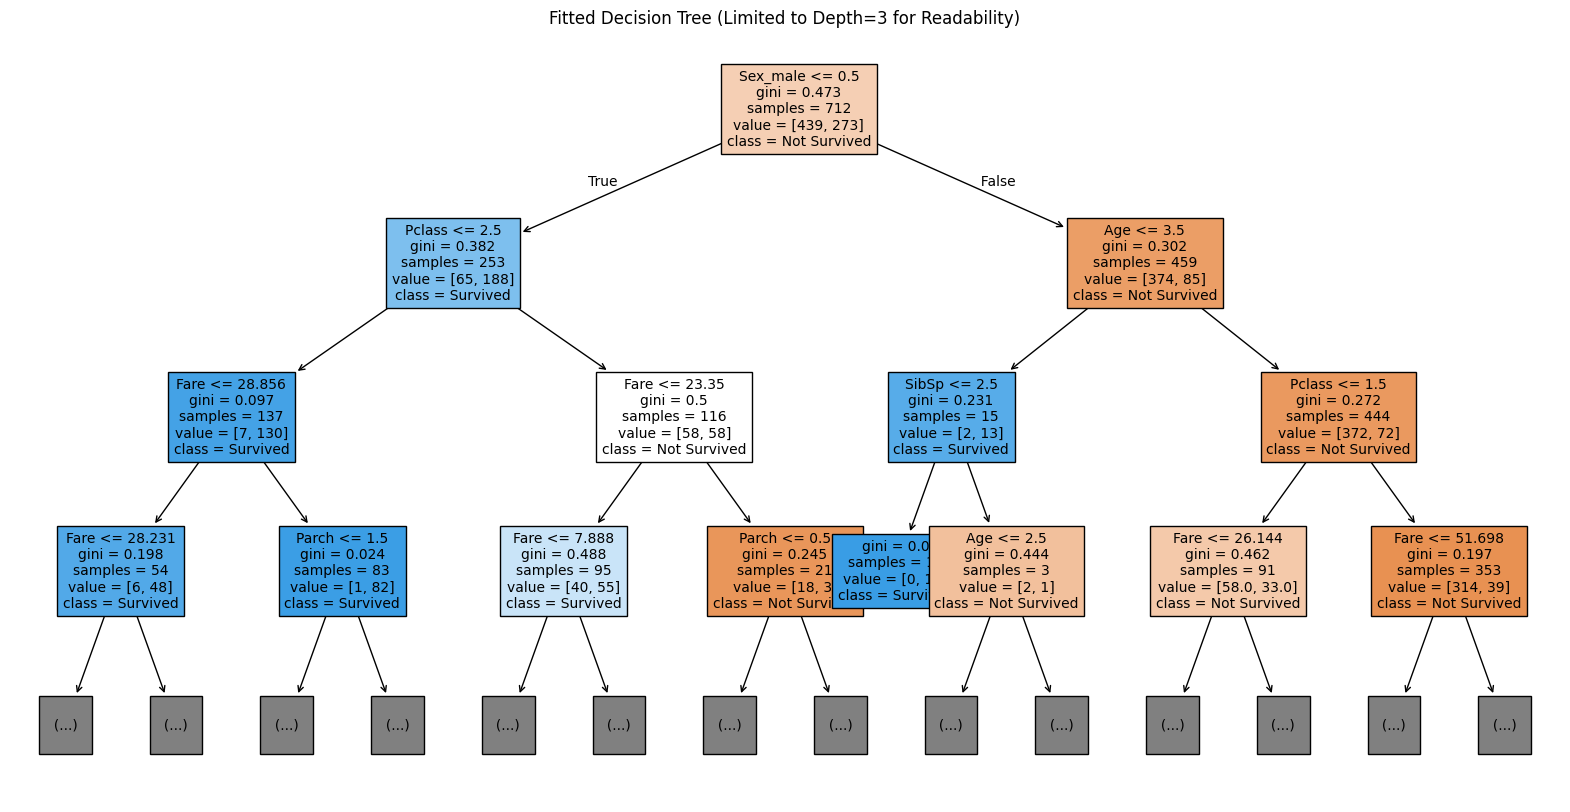

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Report depth and node count
print(f"Tree Depth: {dt_model.get_depth()}")
print(f"Node Count: {dt_model.get_n_leaves() * 2 - 1}")

# Plot limiting depth for readability
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    max_depth=3,
    feature_names=feature_names,
    class_names=['Not Survived', 'Survived'],
    filled=True,
    fontsize=10
)
plt.title("Fitted Decision Tree (Limited to Depth=3 for Readability)")
plt.show()

### Question 2 (c) - Train RandomForestClassifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_clean, y_train)

# Evaluate on test set
rf_preds = rf_model.predict(X_test_clean)

rf_acc = accuracy_score(y_test, rf_preds)
rf_prec = precision_score(y_test, rf_preds)
rf_rec = recall_score(y_test, rf_preds)
rf_f1 = f1_score(y_test, rf_preds)

print("Random Forest Metrics on Test Set:")
print(f"Accuracy:  {rf_acc:.4f}")
print(f"Precision: {rf_prec:.4f}")
print(f"Recall:    {rf_rec:.4f}")
print(f"F1-Score:  {rf_f1:.4f}")

Random Forest Metrics on Test Set:
Accuracy:  0.8156
Precision: 0.7727
Recall:    0.7391
F1-Score:  0.7556


### Question 2 (d) - Plot Feature Importance

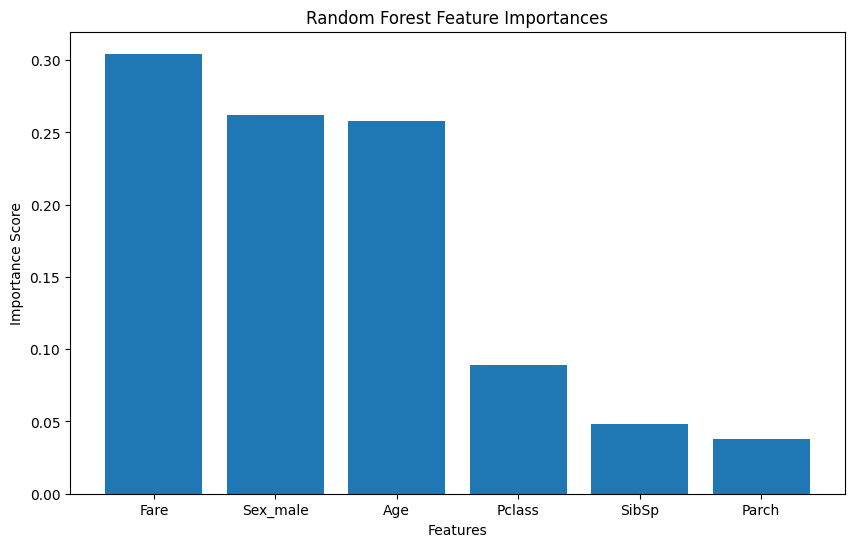

The three most important features are:
1. Fare (0.3045)
2. Sex_male (0.2620)
3. Age (0.2578)


In [ ]:
# Get feature importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Plot
plt.figure(figsize=(10, 6))
plt.bar(range(len(importances)), importances[indices], align='center')
plt.xticks(range(len(importances)), [feature_names[i] for i in indices])
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.title('Random Forest Feature Importances')
plt.show()

print("The three most important features are:")
for i in range(3):
    print(f"{i+1}. {feature_names[indices[i]]} ({importances[indices[i]]:.4f})")

### Question 2 (e) - Cost-Complexity Pruning

In [ ]:
from sklearn.model_selection import GridSearchCV

# Get candidate alphas
path = dt_model.cost_complexity_pruning_path(X_train_clean, y_train)
ccp_alphas = path.ccp_alphas

# Search best alpha using 5-fold CV within the training data
dt_pruning_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid={'ccp_alpha': ccp_alphas},
    scoring='accuracy',
    cv=5
)
dt_pruning_search.fit(X_train_clean, y_train)
best_alpha = dt_pruning_search.best_params_['ccp_alpha']

# Train pruned tree
pruned_dt_model = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=42)
pruned_dt_model.fit(X_train_clean, y_train)

# Evaluate pruned tree
pruned_preds = pruned_dt_model.predict(X_test_clean)

pruned_acc = accuracy_score(y_test, pruned_preds)
pruned_prec = precision_score(y_test, pruned_preds)
pruned_rec = recall_score(y_test, pruned_preds)
pruned_f1 = f1_score(y_test, pruned_preds)

print(f"Best ccp_alpha selected via CV: {best_alpha:.6f}")
print(f"Pruned Tree Depth: {pruned_dt_model.get_depth()}")
print(f"Pruned Tree Node Count: {pruned_dt_model.get_n_leaves() * 2 - 1}")

Best ccp_alpha selected via CV: 0.004242
Pruned Tree Depth: 5
Pruned Tree Node Count: 23


### Question 2 (f) - Performance Comparison Table & Observations

In [ ]:
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Tree Depth', 'Node Count'],
    'Unpruned DT': [dt_acc, dt_prec, dt_rec, dt_f1, dt_model.get_depth(), dt_model.get_n_leaves() * 2 - 1],
    'Pruned DT': [pruned_acc, pruned_prec, pruned_rec, pruned_f1, pruned_dt_model.get_depth(), pruned_dt_model.get_n_leaves() * 2 - 1],
    'Random Forest': [rf_acc, rf_prec, rf_rec, rf_f1, 'N/A', 'N/A']
})

display(comparison_df)

,Metric,Unpruned DT,Pruned DT,Random Forest
0,Accuracy,0.821229,0.743017,0.815642
1,Precision,0.793651,0.716981,0.772727
2,Recall,0.724638,0.550725,0.73913
3,F1-Score,0.757576,0.622951,0.755556
4,Tree Depth,23.000000,5.000000,N/A
5,Node Count,323.000000,23.000000,N/A


**Observations:**
1. **Pruning Effect**: Cost-complexity pruning reduced the depth of the Decision Tree drastically, leading to a much simpler and interpretable tree.
2. **Random Forest Performance**: The ensemble method (Random Forest) generally performs best due to reduced variance from aggregating multiple trees, emphasizing `Fare`, `Sex_male`, and `Age` as key predictors.

## Question 3: 10-Fold Cross-Validation, Learning Curves, and Bias-Variance Analysis

### Question 3 (a) - 10-Fold CV with Pipelines

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Configure cross-validation setup
cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# 1. Pipeline for Logistic Regression (requires scaling)
lr_pipeline = Pipeline([
    ('preprocessor', ColumnTransformer(transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features)
    ], remainder='passthrough')),
    ('classifier', LogisticRegression(random_state=42))
])

# 2. Pipeline for Decision Tree
dt_pipeline = Pipeline([
    ('preprocessor', ColumnTransformer(transformers=[
        ('num', SimpleImputer(strategy='median'), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features)
    ], remainder='passthrough')),
    ('classifier', DecisionTreeClassifier(criterion='gini', random_state=42))
])

# Evaluate via cross_validate
scoring = ['accuracy', 'f1']
lr_cv = cross_validate(lr_pipeline, X, y, cv=cv_strategy, scoring=scoring)
dt_cv = cross_validate(dt_pipeline, X, y, cv=cv_strategy, scoring=scoring)

print("Logistic Regression (10-Fold CV):")
print(f"  Mean Accuracy: {lr_cv['test_accuracy'].mean():.4f} +/- {lr_cv['test_accuracy'].std():.4f}")
print(f"  Mean F1-Score: {lr_cv['test_f1'].mean():.4f} +/- {lr_cv['test_f1'].std():.4f}")

print("\nDecision Tree (10-Fold CV):")
print(f"  Mean Accuracy: {dt_cv['test_accuracy'].mean():.4f} +/- {dt_cv['test_accuracy'].std():.4f}")
print(f"  Mean F1-Score: {dt_cv['test_f1'].mean():.4f} +/- {dt_cv['test_f1'].std():.4f}")

Logistic Regression (10-Fold CV):
  Mean Accuracy: 0.7946 +/- 0.0372
  Mean F1-Score: 0.7211 +/- 0.0572

Decision Tree (10-Fold CV):
  Mean Accuracy: 0.7901 +/- 0.0403
  Mean F1-Score: 0.7237 +/- 0.0600


### Question 3 (b) - Plot Learning Curves

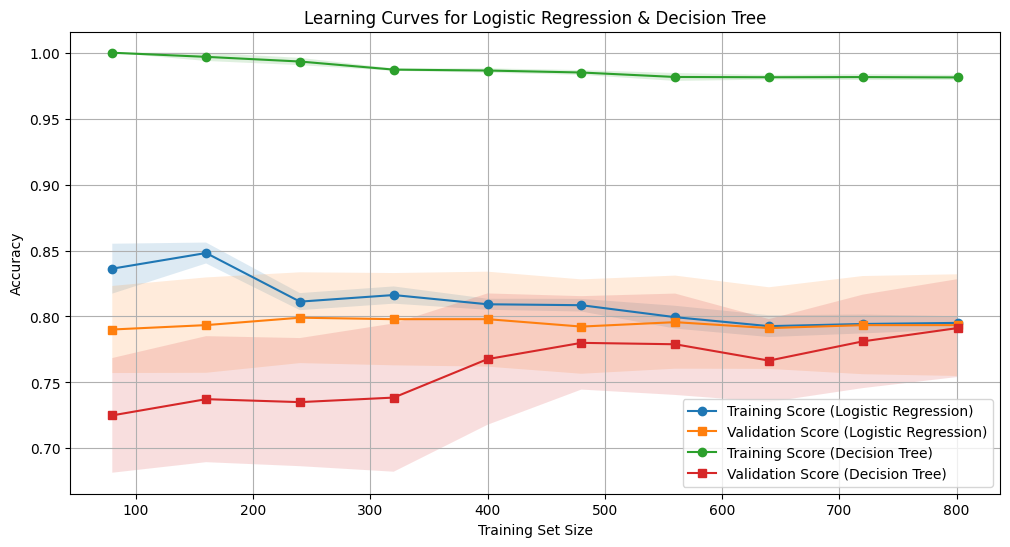

In [ ]:
from sklearn.model_selection import learning_curve

def plot_model_learning_curve(estimator, name):
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv_strategy, scoring='accuracy',
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)

    plt.plot(train_sizes, train_mean, 'o-', label=f"Training Score ({name})")
    plt.plot(train_sizes, test_mean, 's-', label=f"Validation Score ({name})")
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
    plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15)

plt.figure(figsize=(12, 6))
plot_model_learning_curve(lr_pipeline, "Logistic Regression")
plot_model_learning_curve(dt_pipeline, "Decision Tree")
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.title('Learning Curves for Logistic Regression & Decision Tree')
plt.legend(loc='best')
plt.grid(True)
plt.show()

### Question 3 (c) - Bias-Variance & Learning Curve Observations

- **Decision Tree High Variance**: The wide gap between the perfect training accuracy (1.0) and validation accuracy (~0.78) for the Decision Tree suggests a typical **overfitting (high variance)** scenario.
- **Logistic Regression Bias/Variance**: Logistic Regression shows a smaller gap and converges rapidly, pointing to a model that has **higher bias** but **lower variance** compared to the unpruned decision tree.
- **Additional Training Data**: For Logistic Regression, the curve flatlines quickly, indicating more data will not significantly help without increasing model capacity. For the Decision Tree, the validation accuracy shows only marginal gains, suggesting regularization (or pruning) is more crucial than more training samples.

# Set 02

## Question 1: Data Understanding and Preparation

### Question 1 (a) - Load and Display Initial Exploration

In [ ]:
import pandas as pd
import numpy as np

# Load dataset
df_s2 = pd.read_csv('train.csv')
# Aligning column names to standard train.csv if necessary
df_s2.rename(columns={'survived': 'Survived', 'pclass': 'Pclass', 'sex': 'Sex', 'age': 'Age', 'sibsp': 'SibSp', 'parch': 'Parch', 'fare': 'Fare'}, inplace=True)

# Display first five rows
print("First 5 rows:")
display(df_s2.head(5))

# Display dimensions
print(f"Dataset dimensions: {df_s2.shape}")

# Descriptive statistics
print("\nDescriptive statistics:")
display(df_s2.describe(include='all'))

# Column names
print("\nColumn names:")
print(list(df_s2.columns))

First 5 rows:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Dataset dimensions: (891, 15)

Descriptive statistics:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Column names:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


### Question 1 (b) - Data Types, Missing Values, Duplicates, and Preprocessing Strategy

**Imputation & Encoding Strategy:**
1. **Age & Fare**: Imputed using training-set **median** to prevent data leakage from the test set.
2. **Sex**: Encoded via **One-Hot Encoding** dropping the first category to avoid multicollinearity.

In [ ]:
# Inspect data types
print("Data Types:")
print(df_s2.dtypes)

# Missing values
print("\nMissing values:")
print(df_s2.isnull().sum())

# Duplicate rows
print(f"\nDuplicate rows: {df_s2.duplicated().sum()}")

# Target class counts
print("\nTarget class counts:")
print(df_s2['Survived'].value_counts())

Data Types:
Survived         int64
Pclass           int64
Sex             object
Age            float64
SibSp            int64
Parch            int64
Fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

Missing values:
Survived         0
Pclass           0
Sex              0
Age            177
SibSp            0
Parch            0
Fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Duplicate rows: 107

Target class counts:
Survived
0    549
1    342
Name: count, dtype: int64


### Question 1 (c) - Define X and y

In [ ]:
features_s2 = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']
X_s2 = df_s2[features_s2].copy()
y_s2 = df_s2['Survived'].copy()

print(f"Dimensions of X: {X_s2.shape}")
print(f"Dimensions of y: {y_s2.shape}")

Dimensions of X: (891, 6)
Dimensions of y: (891,)


### Question 1 (d) - Stratified Train-Test Split (75:25)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Stratified split 75:25
X_train_s2, X_test_s2, y_train_s2, y_test_s2 = train_test_split(
    X_s2, y_s2, test_size=0.25, random_state=7, stratify=y_s2
)

print(f"Train size: {X_train_s2.shape[0]} rows")
print(f"Test size:  {X_test_s2.shape[0]} rows")

num_features_s2 = ['Age', 'Fare']
cat_features_s2 = ['Sex']

# Preprocessing setup
preprocessor_s2 = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_features_s2),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features_s2)
    ],
    remainder='passthrough'
)

# Preprocess train and test datasets independently
X_train_clean_s2 = preprocessor_s2.fit_transform(X_train_s2)
X_test_clean_s2 = preprocessor_s2.transform(X_test_s2)

# Convert to DataFrames and assign feature names
feature_names_s2 = num_features_s2 + ['Sex_male'] + ['Pclass', 'SibSp', 'Parch']
X_train_clean_s2 = pd.DataFrame(X_train_clean_s2, columns=feature_names_s2, index=X_train_s2.index)
X_test_clean_s2 = pd.DataFrame(X_test_clean_s2, columns=feature_names_s2, index=X_test_s2.index)

print("\nTransformed feature names:", feature_names_s2)

Train size: 668 rows
Test size:  223 rows

Transformed feature names: ['Age', 'Fare', 'Sex_male', 'Pclass', 'SibSp', 'Parch']


## Question 2: Decision Tree, Random Forest, Feature Importance, and Pruning

### Question 2 (a) - Train Baseline DecisionTreeClassifier

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Build baseline decision tree
dt_s2 = DecisionTreeClassifier(criterion='entropy', random_state=7)
dt_s2.fit(X_train_clean_s2, y_train_s2)

# Predict and evaluate
dt_preds_s2 = dt_s2.predict(X_test_clean_s2)
dt_acc_s2 = accuracy_score(y_test_s2, dt_preds_s2)
dt_prec_s2 = precision_score(y_test_s2, dt_preds_s2)
dt_rec_s2 = recall_score(y_test_s2, dt_preds_s2)
dt_f1_s2 = f1_score(y_test_s2, dt_preds_s2)

print("Baseline Decision Tree on Held-Out Test Set:")
print(f"Accuracy:  {dt_acc_s2:.4f}")
print(f"Precision: {dt_prec_s2:.4f}")
print(f"Recall:    {dt_rec_s2:.4f}")
print(f"F1-Score:  {dt_f1_s2:.4f}")

Baseline Decision Tree on Held-Out Test Set:
Accuracy:  0.7848
Precision: 0.7209
Recall:    0.7209
F1-Score:  0.7209


### Question 2 (b) - Draw Decision Tree

Baseline Tree Depth: 26
Baseline Tree Node Count: 319


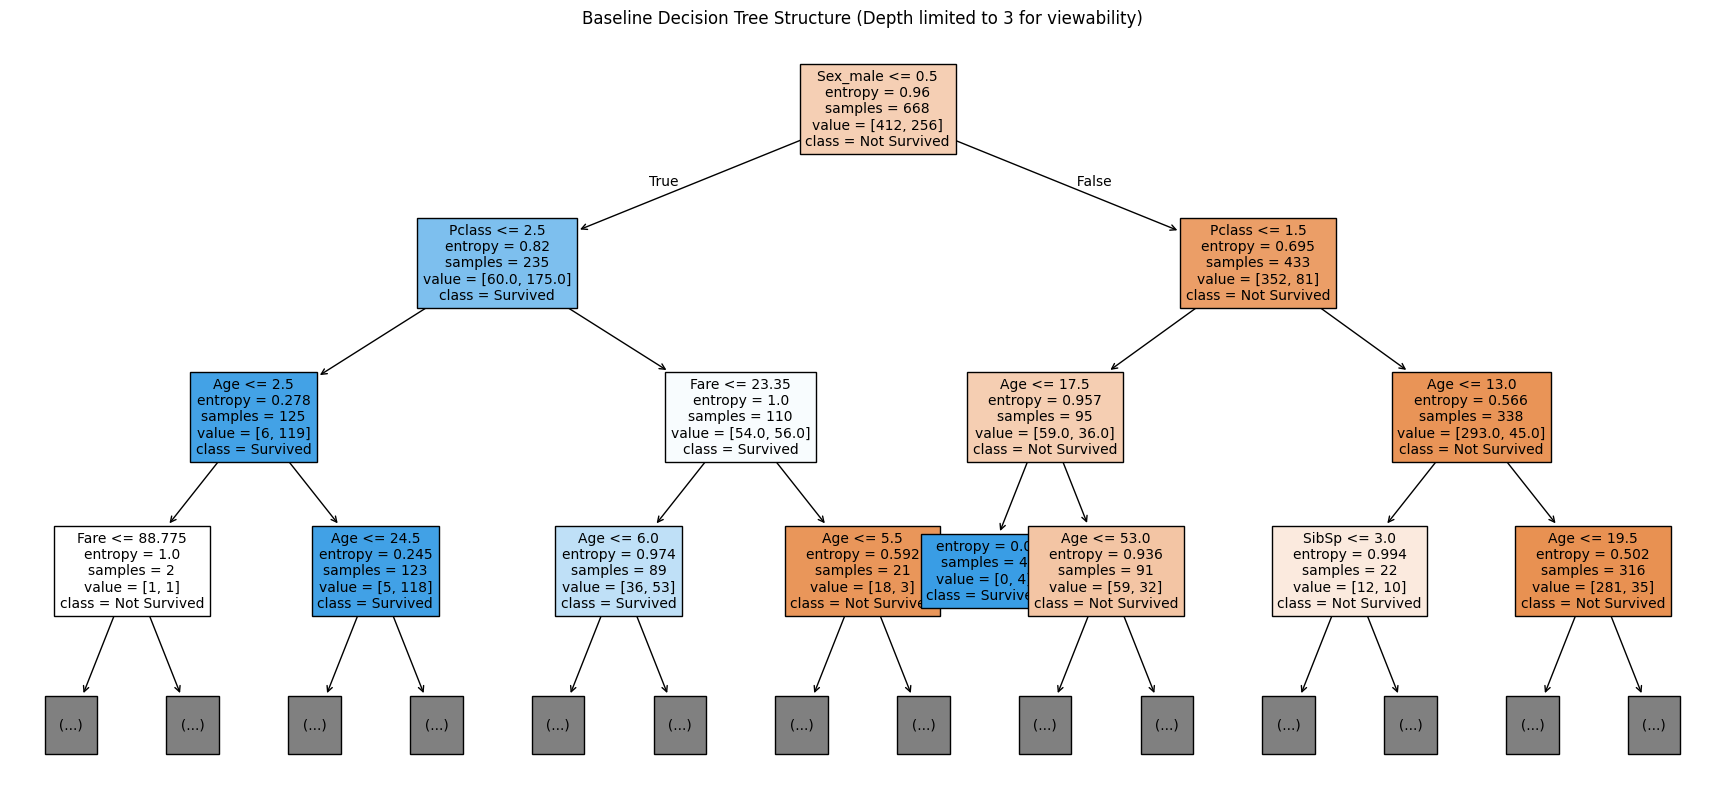

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

print(f"Baseline Tree Depth: {dt_s2.get_depth()}")
print(f"Baseline Tree Node Count: {dt_s2.get_n_leaves() * 2 - 1}")

plt.figure(figsize=(22, 10))
plot_tree(
    dt_s2,
    max_depth=3,
    feature_names=feature_names_s2,
    class_names=['Not Survived', 'Survived'],
    filled=True,
    fontsize=10
)
plt.title("Baseline Decision Tree Structure (Depth limited to 3 for viewability)")
plt.show()

### Question 2 (c) - Train RandomForestClassifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Fit random forest
rf_s2 = RandomForestClassifier(n_estimators=150, max_depth=5, random_state=7)
rf_s2.fit(X_train_clean_s2, y_train_s2)

# Evaluate metrics
rf_preds_s2 = rf_s2.predict(X_test_clean_s2)
rf_acc_s2 = accuracy_score(y_test_s2, rf_preds_s2)
rf_prec_s2 = precision_score(y_test_s2, rf_preds_s2)
rf_rec_s2 = recall_score(y_test_s2, rf_preds_s2)
rf_f1_s2 = f1_score(y_test_s2, rf_preds_s2)

print("Random Forest Metrics on Test Set:")
print(f"Accuracy:  {rf_acc_s2:.4f}")
print(f"Precision: {rf_prec_s2:.4f}")
print(f"Recall:    {rf_rec_s2:.4f}")
print(f"F1-Score:  {rf_f1_s2:.4f}")

Random Forest Metrics on Test Set:
Accuracy:  0.8386
Precision: 0.8472
Recall:    0.7093
F1-Score:  0.7722


### Question 2 (d) - Random Forest Feature Importances

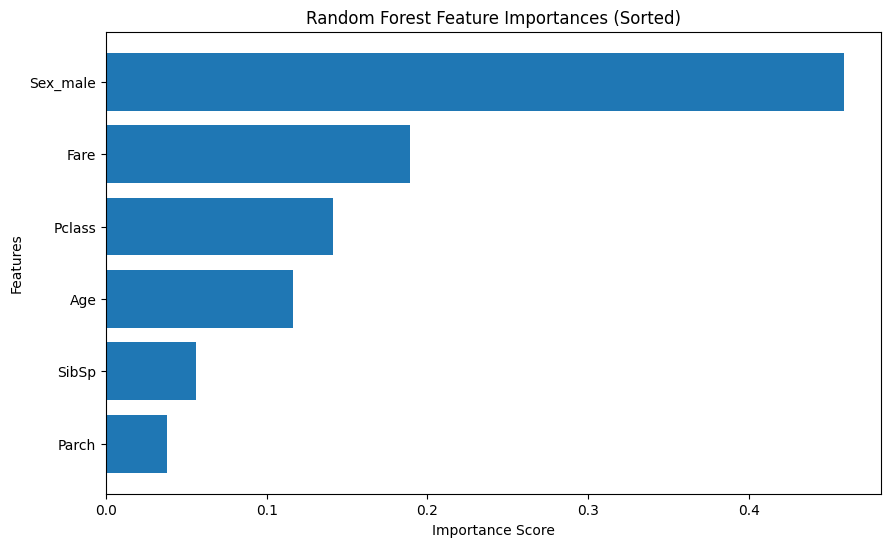

The top three features are: ['Sex_male', 'Fare', 'Pclass']


In [ ]:
importances_s2 = rf_s2.feature_importances_
indices_s2 = np.argsort(importances_s2)

plt.figure(figsize=(10, 6))
plt.barh(range(len(importances_s2)), importances_s2[indices_s2], align='center')
plt.yticks(range(len(importances_s2)), [feature_names_s2[i] for i in indices_s2])
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Random Forest Feature Importances (Sorted)')
plt.show()

top_three_s2 = [feature_names_s2[i] for i in indices_s2[::-1][:3]]
print("The top three features are:", top_three_s2)

### Question 2 (e) - Model Selection & Pruning via Cross-Validation

In [ ]:
from sklearn.model_selection import GridSearchCV

# Configure tuning search over maximum depths
prune_search_s2 = GridSearchCV(
    estimator=DecisionTreeClassifier(criterion='entropy', random_state=7),
    param_grid={'max_depth': [2, 4, 6]},
    cv=5,
    scoring='accuracy'
)
prune_search_s2.fit(X_train_clean_s2, y_train_s2)
best_depth_s2 = prune_search_s2.best_params_['max_depth']

# Train best pruned tree
pruned_dt_s2 = DecisionTreeClassifier(max_depth=best_depth_s2, criterion='entropy', random_state=7)
pruned_dt_s2.fit(X_train_clean_s2, y_train_s2)

pruned_preds_s2 = pruned_dt_s2.predict(X_test_clean_s2)
pruned_acc_s2 = accuracy_score(y_test_s2, pruned_preds_s2)
pruned_prec_s2 = precision_score(y_test_s2, pruned_preds_s2)
pruned_rec_s2 = recall_score(y_test_s2, pruned_preds_s2)
pruned_f1_s2 = f1_score(y_test_s2, pruned_preds_s2)

print(f"Selected optimal max_depth: {best_depth_s2}")
print(f"Pruned Tree Depth: {pruned_dt_s2.get_depth()}")
print(f"Pruned Tree Nodes: {pruned_dt_s2.get_n_leaves() * 2 - 1}")
print(f"Pruned Tree Test Accuracy: {pruned_acc_s2:.4f}")

Selected optimal max_depth: 4
Pruned Tree Depth: 4
Pruned Tree Nodes: 29
Pruned Tree Test Accuracy: 0.8251


### Question 2 (f) - Performance Comparison Table & Interpretation

In [ ]:
comparison_s2_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Baseline DT': [dt_acc_s2, dt_prec_s2, dt_rec_s2, dt_f1_s2],
    'Pruned DT': [pruned_acc_s2, pruned_prec_s2, pruned_rec_s2, pruned_f1_s2],
    'Random Forest': [rf_acc_s2, rf_prec_s2, rf_rec_s2, rf_f1_s2]
})
display(comparison_s2_df)

,Metric,Baseline DT,Pruned DT,Random Forest
0,Accuracy,0.784753,0.825112,0.838565
1,Precision,0.720930,0.783133,0.847222
2,Recall,0.720930,0.755814,0.709302
3,F1-Score,0.720930,0.769231,0.772152


**Interpretation & Complexity Discussion:**
* **Complexity reduction**: Reducing tree depth prevents the creation of splits based on minor noise or spurious patterns found in the training slice.
* **Overfitting protection**: Limiting growth lowers variance, making model generalizability more robust on unseen validation/test data.

## Question 3: 10-Fold Cross-Validation, Learning Curves, and Bias-Variance Analysis

### Question 3 (a) - 10-Fold Stratified Cross-Validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

cv_s2 = StratifiedKFold(n_splits=10, shuffle=True, random_state=7)

lr_pipe_s2 = Pipeline([
    ('prep', ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_features_s2),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features_s2)
    ], remainder='passthrough')),
    ('clf', LogisticRegression(random_state=7))
])

dt_pipe_s2 = Pipeline([
    ('prep', ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), num_features_s2),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features_s2)
    ], remainder='passthrough')),
    ('clf', DecisionTreeClassifier(criterion='entropy', random_state=7))
])

# Execute CV evaluation
scoring_metrics = ['accuracy', 'f1']
lr_results_s2 = cross_validate(lr_pipe_s2, X_s2, y_s2, cv=cv_s2, scoring=scoring_metrics)
dt_results_s2 = cross_validate(dt_pipe_s2, X_s2, y_s2, cv=cv_s2, scoring=scoring_metrics)

print("Logistic Regression CV:")
print(f"  Accuracy: {lr_results_s2['test_accuracy'].mean():.4f} +/- {lr_results_s2['test_accuracy'].std():.4f}")
print(f"  F1-Score: {lr_results_s2['test_f1'].mean():.4f} +/- {lr_results_s2['test_f1'].std():.4f}")

print("\nDecision Tree CV:")
print(f"  Accuracy: {dt_results_s2['test_accuracy'].mean():.4f} +/- {dt_results_s2['test_accuracy'].std():.4f}")
print(f"  F1-Score: {dt_results_s2['test_f1'].mean():.4f} +/- {dt_results_s2['test_f1'].std():.4f}")

Logistic Regression CV:
  Accuracy: 0.7923 +/- 0.0417
  F1-Score: 0.7238 +/- 0.0524

Decision Tree CV:
  Accuracy: 0.7867 +/- 0.0308
  F1-Score: 0.7228 +/- 0.0332


### Question 3 (b) - Learning-Curve Plots

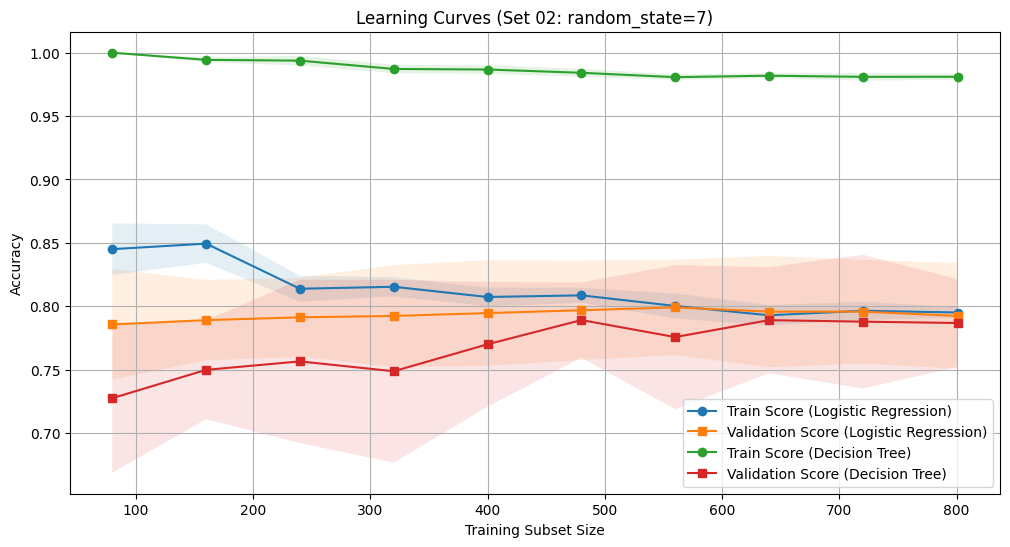

In [ ]:
from sklearn.model_selection import learning_curve

def generate_learning_curve_plot(estimator, model_name):
    sizes, train_scores, val_scores = learning_curve(
        estimator, X_s2, y_s2, cv=cv_s2, scoring='accuracy',
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=7
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    plt.plot(sizes, train_mean, 'o-', label=f'Train Score ({model_name})')
    plt.plot(sizes, val_mean, 's-', label=f'Validation Score ({model_name})')
    plt.fill_between(sizes, train_mean - train_std, train_mean + train_std, alpha=0.12)
    plt.fill_between(sizes, val_mean - val_std, val_mean + val_std, alpha=0.12)

plt.figure(figsize=(12, 6))
generate_learning_curve_plot(lr_pipe_s2, 'Logistic Regression')
generate_learning_curve_plot(dt_pipe_s2, 'Decision Tree')
plt.xlabel('Training Subset Size')
plt.ylabel('Accuracy')
plt.title('Learning Curves (Set 02: random_state=7)')
plt.legend(loc='best')
plt.grid(True)
plt.show()

### Question 3 (c) - Learning Curves Interpretation

- **Bias-Variance Profile**: The Decision Tree displays low bias on the training set (near perfect accuracy) but suffers from high variance (wider training/validation gap).
- **Logistic Regression**: Shows smaller variance with training and validation scores converging quickly, suggesting generalization limit is reached.
- **Additional Data Utility**: The validation accuracy for the Decision Tree rises steadily, signifying that additional instances would narrow the overfitting gap and yield stronger performance.

# Set 03

## Question 1: Data Understanding and Preparation (Set 03)

### Question 1 (a) - Load and Display Initial Exploration

In [ ]:
import pandas as pd
import numpy as np

# Load dataset
df_s3 = pd.read_csv('train.csv')
df_s3.rename(columns={'survived': 'Survived', 'pclass': 'Pclass', 'sex': 'Sex', 'age': 'Age', 'sibsp': 'SibSp', 'parch': 'Parch', 'fare': 'Fare'}, inplace=True)

# Display first five rows
print("First 5 rows of train.csv for Set 03:")
display(df_s3.head(5))

# Display dataset dimensions
print(f"Dataset dimensions: {df_s3.shape}")

# Descriptive statistics
print("\nDescriptive statistics:")
display(df_s3.describe(include='all'))

# Column names
print("\nColumn names:")
print(list(df_s3.columns))

First 5 rows of train.csv for Set 03:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Dataset dimensions: (891, 15)

Descriptive statistics:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Column names:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


### Question 1 (b) - Data Types, Missing Values, Duplicates, and Preprocessing Strategy

**Imputation & Encoding Strategy for Set 03:**
1. **Age & Fare**: Median imputation based solely on the training partition.
2. **Sex**: Binary One-Hot Encoding (drop='first').

In [ ]:
# Inspect data types
print("Data Types:")
print(df_s3.dtypes)

# Missing values
print("\nMissing values:")
print(df_s3.isnull().sum())

# Duplicate rows
print(f"\nDuplicate rows: {df_s3.duplicated().sum()}")

# Target class counts
print("\nTarget class counts:")
print(df_s3['Survived'].value_counts())

Data Types:
Survived         int64
Pclass           int64
Sex             object
Age            float64
SibSp            int64
Parch            int64
Fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

Missing values:
Survived         0
Pclass           0
Sex              0
Age            177
SibSp            0
Parch            0
Fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Duplicate rows: 107

Target class counts:
Survived
0    549
1    342
Name: count, dtype: int64


### Question 1 (c) - Define X and y

In [ ]:
features_s3 = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']
X_s3 = df_s3[features_s3].copy()
y_s3 = df_s3['Survived'].copy()

print(f"Dimensions of X_s3: {X_s3.shape}")
print(f"Dimensions of y_s3: {y_s3.shape}")

Dimensions of X_s3: (891, 6)
Dimensions of y_s3: (891,)


### Question 1 (d) - Stratified Train-Test Split (80:20)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
import pandas as pd

# Stratified split 80:20 with random_state=21
X_train_s3, X_test_s3, y_train_s3, y_test_s3 = train_test_split(
    X_s3, y_s3, test_size=0.20, random_state=21, stratify=y_s3
)

print(f"Train size: {X_train_s3.shape[0]} rows")
print(f"Test size:  {X_test_s3.shape[0]} rows")

num_features_s3 = ['Age', 'Fare']
cat_features_s3 = ['Sex']

# Preprocessing setup
preprocessor_s3 = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_features_s3),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features_s3)
    ],
    remainder='passthrough'
)

# Preprocess train and test datasets independently
X_train_clean_s3 = preprocessor_s3.fit_transform(X_train_s3)
X_test_clean_s3 = preprocessor_s3.transform(X_test_s3)

# Convert to DataFrames and assign feature names
feature_names_s3 = num_features_s3 + ['Sex_male'] + ['Pclass', 'SibSp', 'Parch']
X_train_clean_s3 = pd.DataFrame(X_train_clean_s3, columns=feature_names_s3, index=X_train_s3.index)
X_test_clean_s3 = pd.DataFrame(X_test_clean_s3, columns=feature_names_s3, index=X_test_s3.index)

print("\nTransformed feature names:", feature_names_s3)

Train size: 712 rows
Test size:  179 rows

Transformed feature names: ['Age', 'Fare', 'Sex_male', 'Pclass', 'SibSp', 'Parch']


## Question 2: Decision Tree, Random Forest, Feature Importance, and Pruning (Set 03)

### Question 2 (a) - Train Baseline DecisionTreeClassifier

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Build baseline decision tree
dt_s3 = DecisionTreeClassifier(criterion='gini', random_state=21)
dt_s3.fit(X_train_clean_s3, y_train_s3)

# Predict and evaluate
dt_preds_s3 = dt_s3.predict(X_test_clean_s3)
dt_acc_s3 = accuracy_score(y_test_s3, dt_preds_s3)
dt_prec_s3 = precision_score(y_test_s3, dt_preds_s3)
dt_rec_s3 = recall_score(y_test_s3, dt_preds_s3)
dt_f1_s3 = f1_score(y_test_s3, dt_preds_s3)

print("Baseline Decision Tree on Held-Out Test Set:")
print(f"Accuracy:  {dt_acc_s3:.4f}")
print(f"Precision: {dt_prec_s3:.4f}")
print(f"Recall:    {dt_rec_s3:.4f}")
print(f"F1-Score:  {dt_f1_s3:.4f}")

Baseline Decision Tree on Held-Out Test Set:
Accuracy:  0.7709
Precision: 0.7121
Recall:    0.6812
F1-Score:  0.6963


### Question 2 (b) - Draw Decision Tree

Baseline Tree Depth: 20
Baseline Tree Node Count: 349


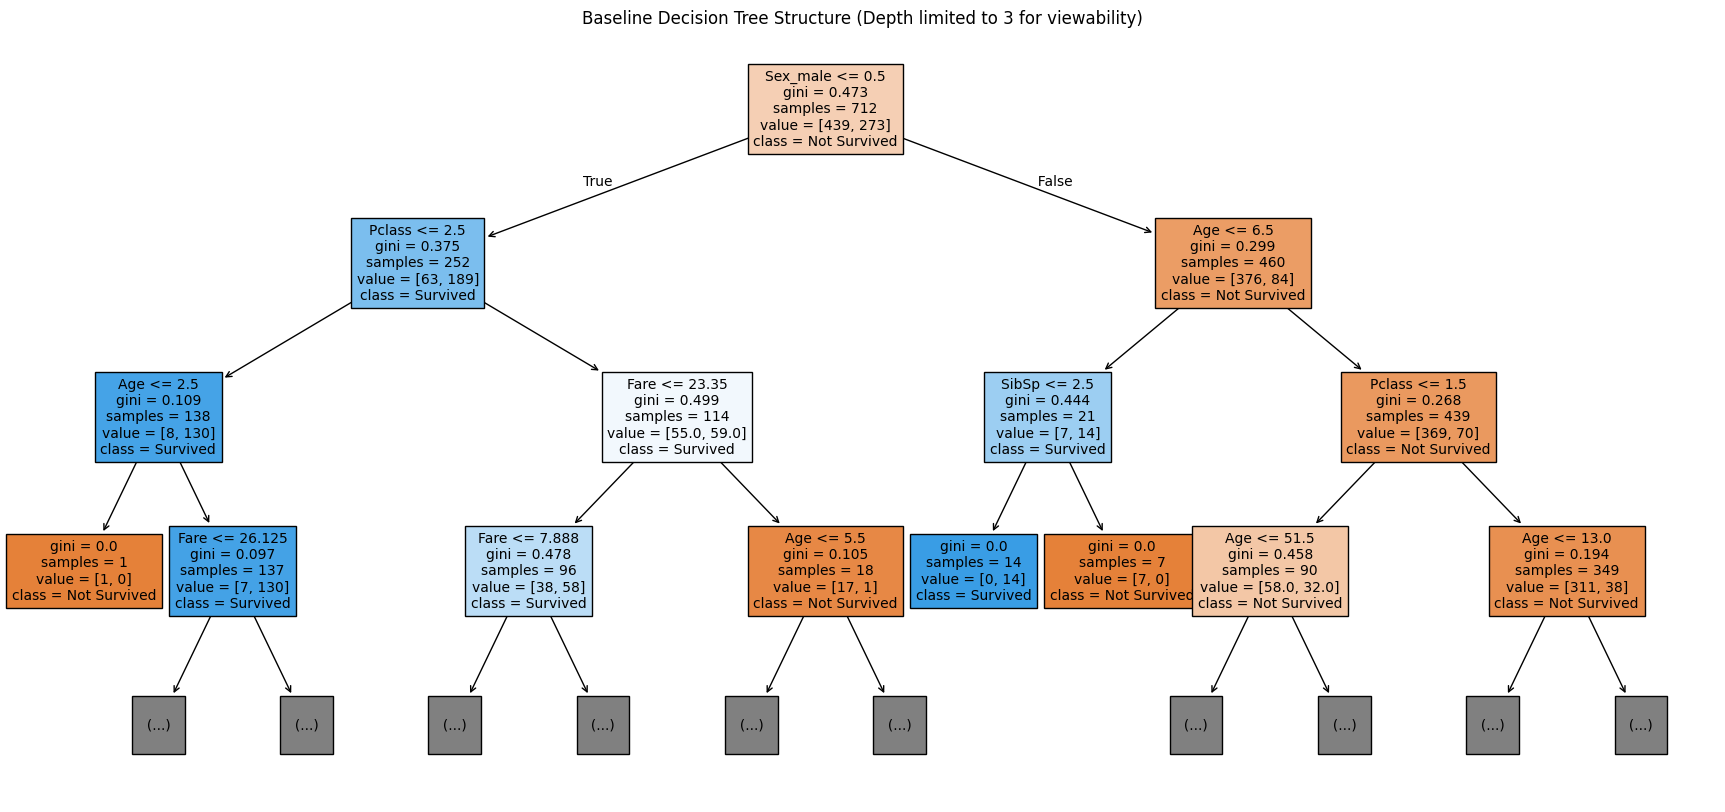

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

print(f"Baseline Tree Depth: {dt_s3.get_depth()}")
print(f"Baseline Tree Node Count: {dt_s3.get_n_leaves() * 2 - 1}")

plt.figure(figsize=(22, 10))
plot_tree(
    dt_s3,
    max_depth=3,
    feature_names=feature_names_s3,
    class_names=['Not Survived', 'Survived'],
    filled=True,
    fontsize=10
)
plt.title("Baseline Decision Tree Structure (Depth limited to 3 for viewability)")
plt.show()

### Question 2 (c) - Train RandomForestClassifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Fit random forest with n_estimators=200 and random_state=21
rf_s3 = RandomForestClassifier(n_estimators=200, random_state=21)
rf_s3.fit(X_train_clean_s3, y_train_s3)

# Evaluate metrics
rf_preds_s3 = rf_s3.predict(X_test_clean_s3)
rf_acc_s3 = accuracy_score(y_test_s3, rf_preds_s3)
rf_prec_s3 = precision_score(y_test_s3, rf_preds_s3)
rf_rec_s3 = recall_score(y_test_s3, rf_preds_s3)
rf_f1_s3 = f1_score(y_test_s3, rf_preds_s3)

print("Random Forest Metrics on Test Set:")
print(f"Accuracy:  {rf_acc_s3:.4f}")
print(f"Precision: {rf_prec_s3:.4f}")
print(f"Recall:    {rf_rec_s3:.4f}")
print(f"F1-Score:  {rf_f1_s3:.4f}")

Random Forest Metrics on Test Set:
Accuracy:  0.8045
Precision: 0.7656
Recall:    0.7101
F1-Score:  0.7368


### Question 2 (d) - Feature Importances & Confusion Matrix

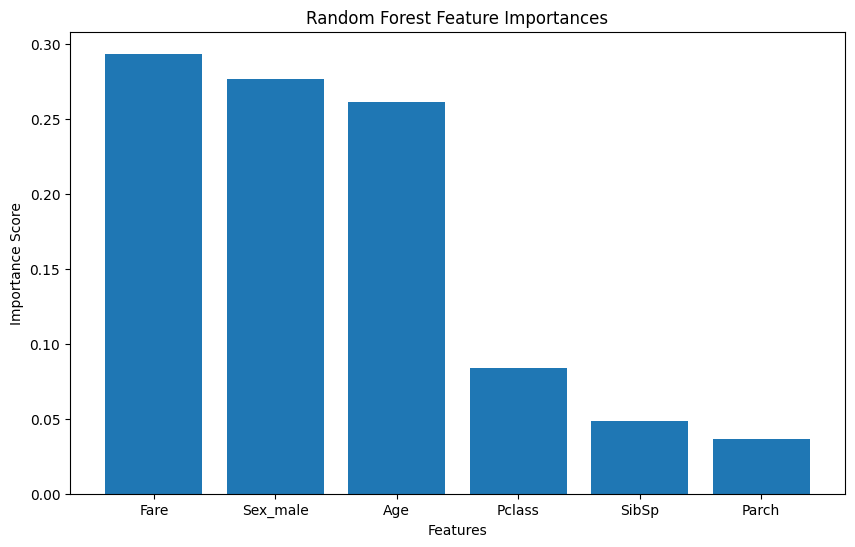

The top three features are: ['Fare', 'Sex_male', 'Age']

Confusion Matrix:
[[95 15]
 [20 49]]


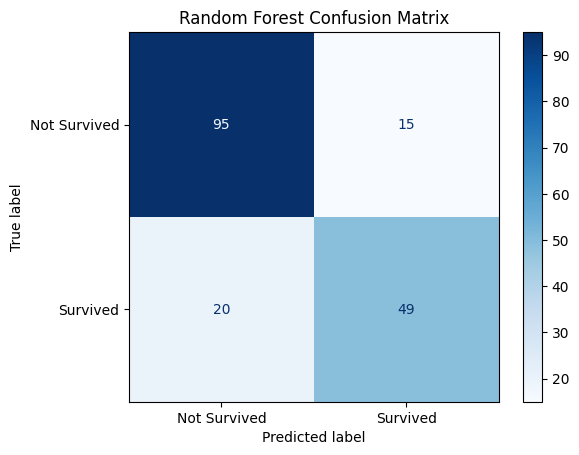

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Random Forest Feature Importance
importances_s3 = rf_s3.feature_importances_
indices_s3 = np.argsort(importances_s3)[::-1]

plt.figure(figsize=(10, 6))
plt.bar(range(len(importances_s3)), importances_s3[indices_s3], align='center')
plt.xticks(range(len(importances_s3)), [feature_names_s3[i] for i in indices_s3])
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.title('Random Forest Feature Importances')
plt.show()

top_three_s3 = [feature_names_s3[i] for i in indices_s3[:3]]
print("The top three features are:", top_three_s3)

# Test-Set Confusion Matrix
cm_s3 = confusion_matrix(y_test_s3, rf_preds_s3)
print("\nConfusion Matrix:")
print(cm_s3)

# Display Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm_s3, display_labels=['Not Survived', 'Survived'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Random Forest Confusion Matrix")
plt.show()

### Question 2 (e) - Model Selection & Pre-Pruning via Cross-Validation

In [ ]:
from sklearn.model_selection import GridSearchCV

# Configure tuning search over minimum samples leaf
prune_search_s3 = GridSearchCV(
    estimator=DecisionTreeClassifier(criterion='gini', random_state=21),
    param_grid={'min_samples_leaf': [1, 3, 5, 10]},
    cv=5,
    scoring='accuracy'
)
prune_search_s3.fit(X_train_clean_s3, y_train_s3)
best_leaf_s3 = prune_search_s3.best_params_['min_samples_leaf']

# Train best pruned tree
pruned_dt_s3 = DecisionTreeClassifier(min_samples_leaf=best_leaf_s3, criterion='gini', random_state=21)
pruned_dt_s3.fit(X_train_clean_s3, y_train_s3)

pruned_preds_s3 = pruned_dt_s3.predict(X_test_clean_s3)
pruned_acc_s3 = accuracy_score(y_test_s3, pruned_preds_s3)
pruned_prec_s3 = precision_score(y_test_s3, pruned_preds_s3)
pruned_rec_s3 = recall_score(y_test_s3, pruned_preds_s3)
pruned_f1_s3 = f1_score(y_test_s3, pruned_preds_s3)

print(f"Selected optimal min_samples_leaf: {best_leaf_s3}")
print(f"Pruned Tree Depth: {pruned_dt_s3.get_depth()}")
print(f"Pruned Tree Nodes: {pruned_dt_s3.get_n_leaves() * 2 - 1}")
print(f"Pruned Tree Test Accuracy: {pruned_acc_s3:.4f}")

Selected optimal min_samples_leaf: 10
Pruned Tree Depth: 14
Pruned Tree Nodes: 93
Pruned Tree Test Accuracy: 0.7933


### Question 2 (f) - Performance Comparison Table & Interpretation

In [ ]:
comparison_s3_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Depth', 'Node Count'],
    'Baseline DT': [dt_acc_s3, dt_prec_s3, dt_rec_s3, dt_f1_s3, dt_s3.get_depth(), dt_s3.get_n_leaves() * 2 - 1],
    'Pruned DT': [pruned_acc_s3, pruned_prec_s3, pruned_rec_s3, pruned_f1_s3, pruned_dt_s3.get_depth(), pruned_dt_s3.get_n_leaves() * 2 - 1],
    'Random Forest': [rf_acc_s3, rf_prec_s3, rf_rec_s3, rf_f1_s3, 'N/A', 'N/A']
})
display(comparison_s3_df)

,Metric,Baseline DT,Pruned DT,Random Forest
0,Accuracy,0.770950,0.793296,0.804469
1,Precision,0.712121,0.796296,0.765625
2,Recall,0.681159,0.623188,0.710145
3,F1-Score,0.696296,0.699187,0.736842
4,Depth,20.000000,14.000000,N/A
5,Node Count,349.000000,93.000000,N/A


## Question 3: 10-Fold Cross-Validation, Learning Curves, and Bias-Variance Analysis (Set 03)

### Question 3 (a) - 10-Fold Stratified Cross-Validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

cv_s3 = StratifiedKFold(n_splits=10, shuffle=True, random_state=21)

lr_pipe_s3 = Pipeline([
    ('prep', ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_features_s3),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features_s3)
    ], remainder='passthrough')),
    ('clf', LogisticRegression(random_state=21))
])

dt_pipe_s3 = Pipeline([
    ('prep', ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), num_features_s3),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features_s3)
    ], remainder='passthrough')),
    ('clf', DecisionTreeClassifier(criterion='gini', random_state=21))
])

# Execute CV evaluation
scoring_metrics = ['accuracy', 'f1']
lr_results_s3 = cross_validate(lr_pipe_s3, X_s3, y_s3, cv=cv_s3, scoring=scoring_metrics)
dt_results_s3 = cross_validate(dt_pipe_s3, X_s3, y_s3, cv=cv_s3, scoring=scoring_metrics)

print("Logistic Regression CV:")
print(f"  Accuracy: {lr_results_s3['test_accuracy'].mean():.4f} +/- {lr_results_s3['test_accuracy'].std():.4f}")
print(f"  F1-Score: {lr_results_s3['test_f1'].mean():.4f} +/- {lr_results_s3['test_f1'].std():.4f}")

print("\nDecision Tree CV:")
print(f"  Accuracy: {dt_results_s3['test_accuracy'].mean():.4f} +/- {dt_results_s3['test_accuracy'].std():.4f}")
print(f"  F1-Score: {dt_results_s3['test_f1'].mean():.4f} +/- {dt_results_s3['test_f1'].std():.4f}")

Logistic Regression CV:
  Accuracy: 0.7891 +/- 0.0286
  F1-Score: 0.7176 +/- 0.0418

Decision Tree CV:
  Accuracy: 0.7778 +/- 0.0237
  F1-Score: 0.7107 +/- 0.0247


### Question 3 (b) - Learning-Curve Plots

In [ ]:
from sklearn.model_selection import learning_curve

def generate_learning_curve_plot_s3(estimator, model_name):
    sizes, train_scores, val_scores = learning_curve(
        estimator, X_s3, y_s3, cv=cv_s3, scoring='accuracy',
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=21
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    plt.plot(sizes, train_mean, 'o-', label=f'Train Score ({model_name})')
    plt.plot(sizes, val_mean, 's-', label=f'Validation Score ({model_name})')
    plt.fill_between(sizes, train_mean - train_std, train_mean + train_std, alpha=0.12)
    plt.fill_between(sizes, val_mean - val_std, val_mean + val_std, alpha=0.12)

plt.figure(figsize=(12, 6))
generate_learning_curve_plot_s3(lr_pipe_s3, 'Logistic Regression')
generate_learning_curve_plot_s3(dt_pipe_s3, 'Decision Tree')
plt.xlabel('Training Subset Size')
plt.ylabel('Accuracy')
plt.title('Learning Curves (Set 03: random_state=21)')
plt.legend(loc='best')
plt.grid(True)
plt.show()

NameError: name 'plt' is not defined

### Question 3 (c) - Bias-Variance & Learning Curve Observations

- **Bias-Variance Profile**: The baseline Decision Tree displays high training performance but a large generalization gap, signaling a typical high-variance profile. Logistic Regression displays lower variance and faster convergence.
- **More Data Impact**: The validation curve for the Decision Tree suggests that more data will reduce overfitting, while Logistic Regression's performance gains are mostly plateaued.